# 3 · Aprender una política: gradientes, ventajas y pasos prudentes

**Lectura acompañada:** §§3.1–3.6, pp. 51–82 de [Murphy, v5](https://arxiv.org/abs/2412.05265v5). Necesitas derivadas elementales, esperanza y las ideas de valor del capítulo 2.

**Objetivo:** entender de dónde sale REINFORCE, comprobar el efecto de un baseline y conectar el estimador con actor-critic, PPO, aprendizaje off-policy y entropía. Implementaremos sus ingredientes en problemas pequeños; no entrenaremos un agente PPO neuronal completo.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

SEMILLA = 2026
np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "grid.alpha": 0.25})

def softmax(theta):
    e = np.exp(theta - np.max(theta, axis=-1, keepdims=True))
    return e / e.sum(axis=-1, keepdims=True)


## 1. §3.1 · Optimizar probabilidades en lugar de elegir un máximo

En el capítulo anterior aprendíamos Q y elegíamos una acción greedy. Ahora describimos directamente una distribución $\pi_\theta(a|s)$. Una política estocástica puede representar soluciones que no son una única acción; en espacios continuos evita enumerar todas las posibilidades.

La identidad $\nabla p=p\nabla\log p$ permite escribir

$$\nabla_\theta J=\mathbb E_{a\sim\pi_\theta}
[r(a)\nabla_\theta\log\pi_\theta(a)].$$

Este caso de un paso contiene el mecanismo básico de REINFORCE. Para una trayectoria aparecen sumas sobre decisiones y retornos futuros. No necesitamos derivar la dinámica del entorno. Sí necesitamos conocer cómo cambia la probabilidad de la acción con los parámetros.

Para logits softmax, la derivada logarítmica es $\nabla_\theta\log\pi(a)=e_a-\pi$. El vector aumenta el logit de la acción elegida y compensa el resto para modificar una distribución normalizada.

## 2. Comprobar la derivada antes de aprender

Con tres acciones y recompensas medias conocidas, podemos calcular la esperanza exacta y contrastar el gradiente con diferencias finitas. Este control detecta signos y factores incorrectos sin depender de que una curva de entrenamiento parezca buena.


In [2]:
medias = np.array([1.0, 0.0, -1.0])
theta = np.array([0.2, -0.1, 0.4])
p = softmax(theta)
grad_exacto = p * (medias - p @ medias)
h = 1e-5
grad_numerico = np.array([
    (softmax(theta + h*np.eye(3)[i]) @ medias
     - softmax(theta - h*np.eye(3)[i]) @ medias) / (2*h)
    for i in range(3)
])
print("Probabilidades:", p)
print("Gradiente analítico:", grad_exacto)
print("Gradiente por diferencias finitas:", grad_numerico)
np.testing.assert_allclose(grad_exacto, grad_numerico, atol=1e-9)
assert np.isclose(grad_exacto.sum(), 0)


Probabilidades: [0.3376 0.2501 0.4123]
Gradiente analítico: [ 0.3628  0.0187 -0.3815]
Gradiente por diferencias finitas: [ 0.3628  0.0187 -0.3815]


La suma cero refleja que sumar una constante a todos los logits no cambia softmax. Esa redundancia también explica por qué su matriz de Fisher puede ser singular si usamos todos los logits sin fijar una referencia.

En tareas secuenciales, usar solo recompensas posteriores a la acción evita multiplicar su gradiente por premios del pasado que no puede causar. Para $J=\mathbb E[\sum_t\gamma^t r_t]$, una formulación por trayectoria con retorno relativo a $t$ incluye $\gamma^t$ fuera del retorno. Algunas formulaciones lo absorben en la distribución de visitas. Aquí usamos un paso y ese factor es uno.

## 3. El baseline conserva la media, no necesariamente la varianza

Como $\mathbb E[\nabla\log\pi(a)]=0$, restar una constante independiente de la acción conserva el gradiente esperado. Con estados, esa constante puede depender de $s$. Debe tratarse como constante en el estimador de la política.

Esto no dice que cualquier baseline sea bueno. Restar un número muy lejano a las recompensas puede aumentar la varianza. Un valor aprendido suele ser útil porque centra la señal cerca de lo esperado, aunque el baseline de mínima varianza tiene un criterio ponderado por el gradiente.

Aislaremos el efecto manteniendo fija la política uniforme. Añadimos 5 a las recompensas: el óptimo no cambia, pero el estimador sin baseline soporta variación adicional.


b=  0.0: media=[ 0.3278  0.0013 -0.3292], traza cov=17.043
b=  5.0: media=[ 0.3318  0.0013 -0.333 ], traza cov=0.387
b=-10.0: media=[ 0.32    0.0015 -0.3215], traza cov=150.357


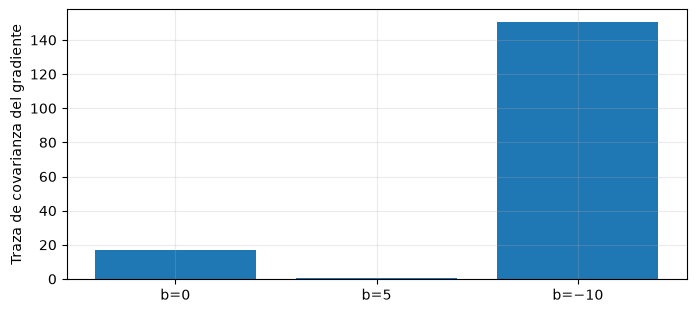

In [3]:
rng = np.random.default_rng(SEMILLA)
acciones = rng.integers(0, 3, 40000)
recompensas = 5 + medias[acciones] + rng.normal(0, 0.5, len(acciones))
score = np.eye(3)[acciones] - 1/3
varianzas = []
for baseline in [0.0, 5.0, -10.0]:
    gradientes = (recompensas - baseline)[:, None] * score
    varianza = gradientes.var(axis=0, ddof=1).sum()
    varianzas.append(varianza)
    print(f"b={baseline:5.1f}: media={gradientes.mean(axis=0)}, traza cov={varianza:.3f}")
plt.bar(["b=0", "b=5", "b=−10"], varianzas)
plt.ylabel("Traza de covarianza del gradiente")
plt.show()


Las medias muestrales no serán idénticas, pero se aproximan al mismo gradiente. El baseline 5 reduce mucho la dispersión; el negativo ilustra que insesgadez y baja varianza son propiedades diferentes.

## 4. Implementar REINFORCE completo en un bandit

Ahora actualizamos los logits. El baseline aprendido utiliza lotes anteriores: primero construimos el gradiente y después actualizamos la media móvil. Si usásemos la misma media de lote sin corregirla, introduciríamos dependencia entre una acción y su baseline.

El registro contiene la recompensa esperada exacta sin el desplazamiento 5. Las recompensas ruidosas sirven para entrenar; la curva exacta reduce ruido de evaluación. Esta ventaja de evaluación es posible porque el laboratorio conoce las medias.


Baseline: False Retorno final medio: 0.9767865626826783


Baseline: True Retorno final medio: 0.9748464002876176


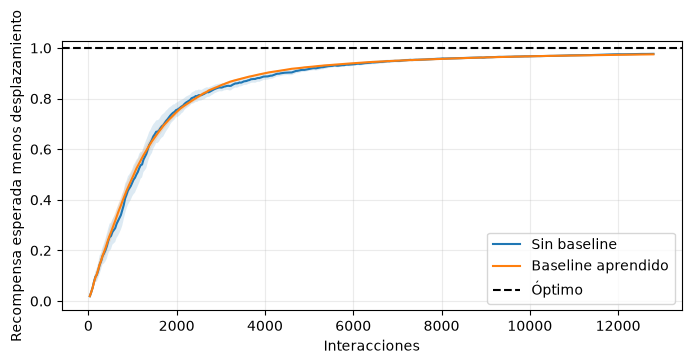

In [4]:
def entrenar(seed, usar_baseline, desplazamiento=5.0, pasos=400, lote=32):
    rng = np.random.default_rng(seed)
    theta = np.zeros(3)
    baseline = 0.0
    curva = []
    for _ in range(pasos):
        p = softmax(theta)
        a = rng.choice(3, lote, p=p)
        r = desplazamiento + medias[a] + rng.normal(0, 0.5, lote)
        ventaja = r - baseline if usar_baseline else r
        gradiente = np.mean(ventaja[:, None] * (np.eye(3)[a] - p), axis=0)
        theta += 0.08 * gradiente
        baseline = 0.9 * baseline + 0.1 * r.mean()
        curva.append(softmax(theta) @ medias)
    return np.array(curva)

for usar in [False, True]:
    datos = np.array([entrenar(SEMILLA+k, usar) for k in range(12)])
    media = datos.mean(axis=0)
    error = 1.96 * datos.std(axis=0, ddof=1) / np.sqrt(len(datos))
    x = np.arange(1, len(media)+1) * 32
    plt.plot(x, media, label="Baseline aprendido" if usar else "Sin baseline")
    plt.fill_between(x, media-error, media+error, alpha=0.15)
    print("Baseline:", usar, "Retorno final medio:", media[-1])
plt.axhline(1, color="black", linestyle="--", label="Óptimo")
plt.xlabel("Interacciones")
plt.ylabel("Recompensa esperada menos desplazamiento")
plt.legend()
plt.show()


No impongas la conclusión «el baseline debe ganar al final». Puede mejorar estabilidad o velocidad sin cambiar mucho el resultado después de suficientes actualizaciones. El control anterior identifica reducción de varianza; esta comparación combina esa reducción con una dinámica de aprendizaje.

## 5. §3.2 · Un crítico transforma el retorno en una ventaja estimada

Un actor decide; un crítico estima valores. El error TD

$$\delta_t=r_t+\gamma(1-d_t)V(s_{t+1})-V(s_t)$$

es una estimación local de ventaja. GAE combina estos errores:

$$\hat A_t=\delta_t+\gamma\lambda(1-d_t)\hat A_{t+1}.$$

Con $\lambda=0$ usamos solo TD. Con $\lambda=1$ y terminal final con valor cero, los términos se telescopan hasta retorno Monte Carlo menos $V(s_t)$. Para valores intermedios mezclamos horizontes. Un crítico inexacto y bootstrap pueden introducir sesgo; no es solo una elección estética.


In [5]:
def gae(recompensas, valores, terminales, gamma=0.95, lam=0.9):
    ventajas = np.zeros(len(recompensas))
    siguiente = 0.0
    for t in reversed(range(len(recompensas))):
        mascara = 1.0 - terminales[t]
        delta = recompensas[t] + gamma*mascara*valores[t+1] - valores[t]
        siguiente = delta + gamma*lam*mascara*siguiente
        ventajas[t] = siguiente
    return ventajas

r = np.array([0.0, 0.0, 1.0])
v = np.array([0.2, 0.4, 0.6, 0.0])
terminales = np.array([False, False, True])
for lam in [0, 0.5, 1]:
    print(f"lambda={lam}:", gae(r, v, terminales, lam=lam))
retornos = np.array([0.95**2, 0.95, 1])
np.testing.assert_allclose(gae(r, v, terminales, lam=1), retornos-v[:-1])


lambda=0: [0.18 0.17 0.4 ]
lambda=0.5: [0.351 0.36  0.4  ]
lambda=1: [0.7025 0.55   0.4   ]


El gradiente natural mide el tamaño del cambio en distribuciones mediante la geometría de Fisher. DDPG usa un actor determinista y el gradiente de un crítico para acciones continuas; TD3 combina dos críticos, retraso del actor y suavizado de objetivos. WPO propone otra geometría, basada en transporte. Comparten la necesidad de controlar errores del crítico y coordinar velocidades de aprendizaje.

## 6. §3.3 · Por qué una buena dirección puede dar un mal paso

Una mejora local no justifica desplazar mucho la política. TRPO aproxima una actualización con restricción de KL. PPO utiliza un objetivo recortado:

$$L=\min\{\rho A,\operatorname{clip}(\rho,1-\epsilon,1+\epsilon)A\},\qquad
\rho=\frac{\pi_\theta(a|s)}{\pi_{\rm old}(a|s)}.$$

Con ventaja positiva desaparece el incentivo del objetivo a aumentar mucho esa probabilidad. Con ventaja negativa desaparece el incentivo a reducirla más allá del otro límite. La función no recorta simétricamente todos los cambios: dibujar ambos signos ayuda a entenderlo.


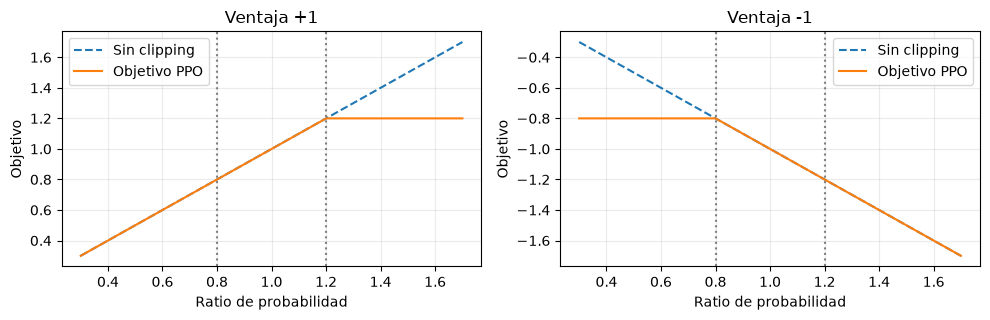

In [6]:
ratios = np.linspace(0.3, 1.7, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
for ax, ventaja in zip(axes, [1.0, -1.0]):
    sin_recorte = ratios * ventaja
    recortado = np.minimum(sin_recorte, np.clip(ratios, 0.8, 1.2) * ventaja)
    ax.plot(ratios, sin_recorte, "--", label="Sin clipping")
    ax.plot(ratios, recortado, label="Objetivo PPO")
    ax.axvline(0.8, color="gray", linestyle=":")
    ax.axvline(1.2, color="gray", linestyle=":")
    ax.set(title=f"Ventaja {ventaja:+.0f}", xlabel="Ratio de probabilidad", ylabel="Objetivo")
    ax.legend()
plt.tight_layout()
plt.show()


El recorte limita incentivos de esta pérdida, pero no fija una cota dura a la KL global. Una red comparte parámetros: cambiar una probabilidad mueve otras. Se siguen monitorizando KL, entropía y rendimiento. VMPO aborda la mejora con una distribución auxiliar y una proyección, otra forma de controlar el desplazamiento.

## 7. §3.4 · Reutilizar datos de otra política tiene un precio

Si muestreamos con $\mu$ y queremos evaluar $\pi$, el peso $\pi(a)/\mu(a)$ corrige la distribución cuando existe soporte. Si $\mu$ nunca elige una acción que $\pi$ necesita, ninguna división recupera esa información.

En secuencias largas, los productos de razones pueden ser extremos. V-trace y Retrace recortan correcciones con construcciones específicas; IMPALA usa estas ideas para actores distribuidos que pueden ir retrasados respecto al aprendiz. Recortar pesos de cualquier manera puede introducir sesgo.


In [7]:
rng = np.random.default_rng(SEMILLA)
objetivo = np.array([0.05, 0.05, 0.90])
for comportamiento in [np.ones(3)/3, np.array([0.495, 0.495, 0.01])]:
    a = rng.choice(3, 20000, p=comportamiento)
    pesos = objetivo[a] / comportamiento[a]
    estimacion = np.mean(pesos * medias[a])
    ess = pesos.sum()**2 / np.sum(pesos**2)
    print("Política de datos:", comportamiento)
    print("Estimación:", round(estimacion, 4), "Valor exacto:", objetivo @ medias,
          "ESS diagnóstico:", round(ess, 1))


Política de datos: [0.3333 0.3333 0.3333]
Estimación: -0.8466 Valor exacto: -0.85 ESS diagnóstico: 8156.8
Política de datos: [0.495 0.495 0.01 ]
Estimación: -0.7728 Valor exacto: -0.85 ESS diagnóstico: 230.2


El tamaño efectivo de muestra es un diagnóstico de concentración de pesos, no una garantía universal de calidad. En el segundo caso casi toda la información relevante viene de pocas acciones raras.

## 8. §§3.5–3.6 · Buscar sin derivadas y regularizar distribuciones

La búsqueda aleatoria y las estrategias evolutivas optimizan parámetros mediante evaluaciones de políticas. Pueden funcionar sin derivadas de la política, pero deben pagar evaluaciones completas y controlar su ruido. No son equivalentes a explorar acciones dentro de una trayectoria.

La perspectiva de RL como inferencia favorece trayectorias de alta recompensa y conecta con objetivos que incluyen entropía o KL. En un bandit, maximizar $\sum_a p_a r_a+\tau H(p)$ da $p_a\propto\exp(r_a/\tau)$. Cuanto mayor la temperatura, más diversidad se conserva.

MPO alterna construcción de una distribución mejorada y ajuste de la política. AWR/AWAC ponderan acciones por ventajas. SAC combina política estocástica, críticos y recompensa más entropía en problemas secuenciales. La inferencia activa relaciona decisiones con preferencias e información, pero no basta renombrar una recompensa para hacer idénticos todos estos marcos.


Temperatura=0.1: p=[1. 0. 0.], retorno=1.000, H=0.000
Temperatura=0.5: p=[0.8668 0.1173 0.0159], retorno=0.851, H=0.441
Temperatura=2.0: p=[0.5065 0.3072 0.1863], retorno=0.320, H=1.020


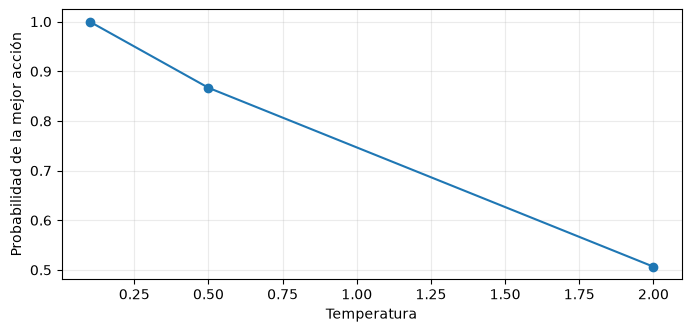

In [8]:
temperaturas = [0.1, 0.5, 2.0]
for temperatura in temperaturas:
    p = softmax(medias / temperatura)
    entropia = -np.sum(p * np.log(p))
    print(f"Temperatura={temperatura}: p={p}, retorno={p@medias:.3f}, H={entropia:.3f}")
plt.plot(temperaturas, [softmax(medias/t)[0] for t in temperaturas], "o-")
plt.xlabel("Temperatura")
plt.ylabel("Probabilidad de la mejor acción")
plt.show()


## 9. Ejercicio: separar recompensa, varianza y óptimo

Repite REINFORCE con desplazamientos 0 y 10. En este bandit sumar una constante no cambia la mejor política ni el gradiente esperado, pero sí puede cambiar la varianza. Mantén el mismo número de interacciones.


In [9]:
for desplazamiento in [0, 10]:
    for baseline in [False, True]:
        finales = [entrenar(SEMILLA+k, baseline, desplazamiento)[-1] for k in range(8)]
        print(f"Desplazamiento={desplazamiento}, baseline={baseline}: "
              f"{np.mean(finales):.4f} ± {np.std(finales, ddof=1):.4f} (desv. entre semillas)")


Desplazamiento=0, baseline=False: 0.9752 ± 0.0007 (desv. entre semillas)
Desplazamiento=0, baseline=True: 0.9748 ± 0.0015 (desv. entre semillas)


Desplazamiento=10, baseline=False: 0.9792 ± 0.0068 (desv. entre semillas)


Desplazamiento=10, baseline=True: 0.9745 ± 0.0016 (desv. entre semillas)


<details>
<summary>Solución orientativa</summary>

El desplazamiento desaparece del gradiente exacto porque multiplica una derivada logarítmica de esperanza cero. En muestras finitas añade dispersión si no se centra adecuadamente. El baseline aprendido tarda en adaptarse: al principio no equivale al baseline exacto.

No extiendas sin más esta invariancia a episodios de duración variable: añadir un premio por paso puede favorecer episodios más largos. Tampoco uses la desviación entre semillas como si fuese la incertidumbre de la media.

</details>

Para el grupo: explica por qué el clipping no garantiza una mejora, qué sucede si el baseline depende de la acción y qué pierde una corrección off-policy sin soporte. En el capítulo 6 reaparecerán estas mismas ideas al optimizar respuestas.

**Fuente:** adaptación de [Murphy, capítulo 3](https://arxiv.org/html/2412.05265v5#Ch3), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Ejemplos propios. [Resumen y experimento de referencia](../docs/03_politicas.md).
